##### Feladat (Példatár 4.2)

Egy $L = 1 ~\mathrm{m}$ hosszú, $d = 10 ~\mathrm{mm}$ átmérőjű egyenes rúd végein $F = 1 ~\mathrm{kN}$ húzóerő, $M_1$ hajlító- és $M_2$ csavarónyomaték működik. Hogyan válasszuk meg az $M_1/F$ és $M_2/F$ arányt, ha azt akarjuk, hogy az egyes terhelések hatására azonos mértékű alakváltozási energia halmozódjon fel a rúdban? Mekkora lesz ebben az esetben a teljes alakváltozási energia? A rúd anyagának rugalmassági modulusza $E = 200 ~\mathrm{GPa}$, Poisson-tényezője $\nu = 0.3$.

Adatok: $L = 1 ~\mathrm{m}$, $d = 10 ~\mathrm{mm}$, $F = 1 ~\mathrm{kN}$, $E = 200 ~\mathrm{GPa}$, $\nu = 0.3$.

Feladatok:

a) Hogyan válasszuk meg az $M_1/F$ és $M_2/F$ arányt, hogy $U_N = U_{M_h} = U_{M_t}$ legyen?

b) Mekkora lesz ebben az esetben a teljes alakváltozási energia?

<img src="img/01.jpg" alt="Feladat" width=450px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
L_data = 1 # m
d_data = 10 # mm
F_data = 1 # kN
E_data = 200 # GPa
nu_data = 0.3

# Átváltás N, mm, MPa rendszerbe
L_data = L_data * 10**3 # mm
F_data = F_data * 10**3 # N
E_data = E_data * 10**3 # MPa

In [3]:
L, d, F, E, nu = sp.symbols('L, d, F, E, nu', positive=True)
M_1, M_2 = sp.symbols('M_1, M_2', positive=True) # Ismeretlen nyomatékok
x = sp.Symbol('x')

In [4]:
data = [(L, L_data),
        (d, d_data),
        (F, F_data),
        (E, E_data),
        (nu, nu_data)]

#### a) Az $M_1/F$ és $M_2/F$ arány

##### Alakváltozási energia

A rúdban felhalmozódó alakváltozási energia az egyes igénybevételekből adódó alakváltozási energiák összege:

$$U = U_N + U_{M_h} + U_{M_t} = \int_0^L \frac{N^2(x)}{2AE} \, dx + \int_0^L \frac{M_h^2(x)}{2IE} \, dx + \int_0^L \frac{M_t^2(x)}{2I_pG} \, dx$$

ahol:
- $U_N$: a normál igénybevételből (húzásból) adódó alakváltozási energia,
- $U_{M_h}$: a hajlító igénybevételből adódó alakváltozási energia,
- $U_{M_t}$: a csavaró igénybevételből adódó alakváltozási energia,
- $A$: a keresztmetszet területe,
- $I$: a keresztmetszet másodrendű nyomatéka,
- $I_p$: a keresztmetszet poláris másodrendű nyomatéka,
- $E$: a rugalmassági modulusz,
- $G$: a csúsztató rugalmassági modulusz.

##### Igénybevételek

A rúd minden keresztmetszetében ugyanazok az igénybevételek működnek:

$$N(x) = F, \qquad M_h(x) = M_1, \qquad M_t(x) = M_2$$

Így az integrandusok minden keresztmetszetben konstansok, az integrálás a rúd $L$ hosszával való szorzást jelenti.

##### Keresztmetszeti jellemzők

In [5]:
# Kör keresztmetszet területe
A = d**2 * sp.pi / 4
display(Math(rf'A = \frac{{d^2 \pi}}{{4}} = {latex(round(A.subs(data), 3))} ~\mathrm{{mm^2}}'))

# Másodrendű nyomaték
I = d**4 * sp.pi / 64
display(Math(rf'I = \frac{{d^4 \pi}}{{64}} = {latex(round(I.subs(data), 3))} ~\mathrm{{mm^4}}'))

# Poláris másodrendű nyomaték
I_p = d**4 * sp.pi / 32
display(Math(rf'I_p = \frac{{d^4 \pi}}{{32}} = {latex(round(I_p.subs(data), 3))} ~\mathrm{{mm^4}}'))

# Csúsztató rugalmassági modulusz
G = E / (2 * (1 + nu))
display(Math(rf'G = \frac{{E}}{{2 (1 + \nu)}} = {latex(round(G.subs(data), 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Normál igénybevételből adódó alakváltozási energia

In [6]:
N = F # Normál igénybevétel (húzás)

U_N = sp.integrate(N**2 / (2*A*E), (x, 0, L))
display(Math(rf'U_N = \int_0^L \frac{{N^2}}{{2AE}} \, dx = \frac{{N^2 \cdot L}}{{2AE}} = {latex(U_N)} = {latex(round(U_N.subs(data), 3))} ~\mathrm{{Nmm}}'))

<IPython.core.display.Math object>

##### Hajlító igénybevételből adódó alakváltozási energia

In [7]:
M_h = M_1 # Hajlító igénybevétel

U_Mh = sp.integrate(M_h**2 / (2*I*E), (x, 0, L))
display(Math(rf'U_{{M_h}} = \int_0^L \frac{{M_h^2}}{{2IE}} \, dx = \frac{{M_h^2 \cdot L}}{{2IE}} = {latex(U_Mh)}'))

<IPython.core.display.Math object>

##### Csavaró igénybevételből adódó alakváltozási energia

In [8]:
M_t = M_2 # Csavaró igénybevétel

U_Mt = sp.simplify(sp.integrate(M_t**2 / (2*I_p*G), (x, 0, L)))
display(Math(rf'U_{{M_t}} = \int_0^L \frac{{M_t^2}}{{2I_pG}} \, dx = \frac{{M_t^2 \cdot L}}{{2I_pG}} = {latex(U_Mt)}'))

<IPython.core.display.Math object>

##### Az $U_N = U_{M_h}$ feltételből

In [9]:
eq1 = U_N - U_Mh
display(Math(rf'U_N = U_{{M_h}} \quad \longrightarrow \quad {latex(U_N)} = {latex(U_Mh)}'))

# Rendszer megoldása
sol = sp.solve(eq1, M_1)
M_1_sol = sol[0]
display(Math(rf'\frac{{M_1}}{{F}} = {latex(M_1_sol / F)} = {latex(round((M_1_sol / F).subs(data), 3))} ~\mathrm{{mm}}'))
display(Math(rf'M_1 = {latex(M_1_sol)} = {latex(round(M_1_sol.subs(data), 3))} ~\mathrm{{Nmm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Az $U_N = U_{M_t}$ feltételből

In [10]:
eq2 = U_N - U_Mt
display(Math(rf'U_N = U_{{M_t}} \quad \longrightarrow \quad {latex(U_N)} = {latex(U_Mt)}'))

# Rendszer megoldása
sol = sp.solve(eq2, M_2)
M_2_sol = sol[0]
display(Math(rf'\frac{{M_2}}{{F}} = {latex(M_2_sol / F)} = {latex(round((M_2_sol / F).subs(data), 3))} ~\mathrm{{mm}}'))
display(Math(rf'M_2 = {latex(M_2_sol)} = {latex(round(M_2_sol.subs(data), 3))} ~\mathrm{{Nmm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### b) A teljes alakváltozási energia

Az a) feladatrész feltétele miatt a három igénybevételből azonos alakváltozási energia halmozódik fel, így:

$$U = U_N + U_{M_h} + U_{M_t} = 3 \cdot U_N$$

In [11]:
# Alakváltozási energiák a kapott nyomatékokkal
U_Mh_sol = U_Mh.subs(M_1, M_1_sol)
U_Mt_sol = sp.simplify(U_Mt.subs(M_2, M_2_sol))
display(Math(rf'U_N = {latex(round(U_N.subs(data), 3))} ~\mathrm{{Nmm}}, \qquad U_{{M_h}} = {latex(round(U_Mh_sol.subs(data), 3))} ~\mathrm{{Nmm}}, \qquad U_{{M_t}} = {latex(round(U_Mt_sol.subs(data), 3))} ~\mathrm{{Nmm}}'))

# Teljes alakváltozási energia
U = sp.simplify(U_N + U_Mh_sol + U_Mt_sol)
display(Math(rf'U = U_N + U_{{M_h}} + U_{{M_t}} = 3 \cdot U_N = {latex(U)} = {latex(round(U.subs(data), 3))} ~\mathrm{{Nmm}} = {latex(round(U.subs(data) / 10**3, 4))} ~\mathrm{{Nm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ábrázolás

Az alakváltozási energiák a nyomaték függvényében: $U_N$ nem függ a nyomatéktól, míg $U_{M_h}$ és $U_{M_t}$ a nyomaték négyzetével arányos. A görbék metszéspontjai adják az $M_1$ és $M_2$ nyomatékokat.

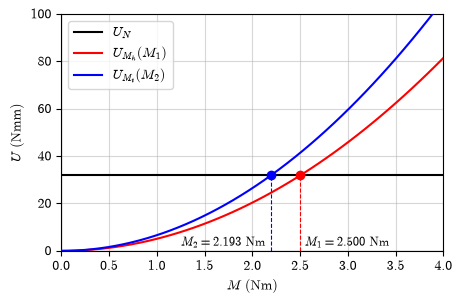

In [12]:
M = sp.Symbol('M') # Nyomaték (Nmm)

# Numerikus függvények
U_Mh_num = sp.lambdify(M, U_Mh.subs(M_1, M).subs(data), modules='numpy')
U_Mt_num = sp.lambdify(M, U_Mt.subs(M_2, M).subs(data), modules='numpy')

# Nevezetes pontok
U_N_num = float(U_N.subs(data))
M_1_num = float(M_1_sol.subs(data))
M_2_num = float(M_2_sol.subs(data))

# x értékek
M_vals = np.linspace(0, 4000)

# y értékek
U_N_vals = np.full_like(M_vals, U_N_num)
U_Mh_vals = U_Mh_num(M_vals)
U_Mt_vals = U_Mt_num(M_vals)

# Ábrázolás
plt.figure(figsize=(12/2.54, 8/2.54))
plt.plot(M_vals*1e-3, U_N_vals, color='black', zorder=5, label=r'$U_N$')
plt.plot(M_vals*1e-3, U_Mh_vals, color='red', zorder=5, label=r'$U_{M_h}(M_1)$')
plt.plot(M_vals*1e-3, U_Mt_vals, color='blue', zorder=5, label=r'$U_{M_t}(M_2)$')
plt.plot([M_1_num*1e-3, M_1_num*1e-3], [0, U_N_num], color='red', linestyle='--', linewidth=0.8)
plt.plot([M_2_num*1e-3, M_2_num*1e-3], [0, U_N_num], color='blue', linestyle='--', linewidth=0.8)
plt.scatter(M_1_num*1e-3, U_N_num, color='red', zorder=6)
plt.scatter(M_2_num*1e-3, U_N_num, color='blue', zorder=6)
plt.text(M_1_num*1e-3 + 0.05, 2, rf'$M_1 = {M_1_num*1e-3:.3f} ~\mathrm{{Nm}}$', ha='left', fontsize=9)
plt.text(M_2_num*1e-3 - 0.05, 2, rf'$M_2 = {M_2_num*1e-3:.3f} ~\mathrm{{Nm}}$', ha='right', fontsize=9)
plt.axvline(0, color='black', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel(r'$M ~ \mathrm{(Nm)}$')
plt.ylabel(r'$U ~ \mathrm{(Nmm)}$')
plt.grid(True, alpha=0.5)
plt.xlim(0, 4)
plt.ylim(0, 100)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('alakvaltozasi_energia.pdf')
plt.show()

Ha $M_1 / F = d/4$ és $M_2 / F = d / \left( 4\sqrt{1 + \nu} \right)$, akkor a három terhelés hatására azonos mértékű alakváltozási energia halmozódik fel a rúdban, a teljes alakváltozási energia $U \approx 0.095 ~\mathrm{Nm}$.